In [17]:
import os
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras.utils import to_categorical
from tensorflow.keras import layers, models
from tensorflow.keras.applications import ResNet101V2
from tensorflow.keras.callbacks import ModelCheckpoint
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.utils.class_weight import compute_class_weight
from sklearn.model_selection import train_test_split

In [18]:
TRAIN_GROUNDTRUTH_PATH = "/Users/mac/Development/diploma/skin-mutation-detection/data/train/ISIC_2019_Training_GroundTruth.csv"

TRAIN_IMAGE_DIR = "/Users/mac/Development/diploma/skin-mutation-detection/data/train/ISIC_2019_Training_Input"

IMG_SIZE = (456, 456)
BATCH_SIZE = 32
EPOCHS = 20
LABELS = ['MEL', 'NV', 'BCC', 'AK', 'BKL', 'DF', 'VASC', 'SCC']

In [19]:
def read_ds(gnd_path):
    df = pd.read_csv(gnd_path)
    return df

def get_image_paths_and_labels(df, image_dir):
    image_paths = [os.path.join(image_dir, row['image'] + '.jpg') for _, row in df.iterrows()]
    labels = df[LABELS].values  # One-hot labels
    return image_paths, labels

train_groundtruth = read_ds(TRAIN_GROUNDTRUTH_PATH)

train_paths, train_labels = get_image_paths_and_labels(train_groundtruth, TRAIN_IMAGE_DIR)

In [20]:

train_paths, temp_paths, train_labels, temp_labels = train_test_split(
    train_paths, train_labels, test_size=0.2, stratify=train_labels, random_state=42
)

val_paths, test_paths, val_labels, test_labels = train_test_split(
    temp_paths, temp_labels, test_size=0.5, stratify=temp_labels, random_state=42
)

In [21]:
def load_image(file_path, label):
    img = tf.io.read_file(file_path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, IMG_SIZE)
    img = tf.keras.applications.efficientnet.preprocess_input(img)
    return img, label

def preprocess_and_augment(file_path, label):
    img, label = load_image(file_path, label)
    img = tf.image.random_flip_left_right(img)
    img = tf.image.random_flip_up_down(img)
    img = tf.image.random_brightness(img, max_delta=0.2)
    img = tf.image.random_contrast(img, lower=0.8, upper=1.2)
    return img, label

train_dataset = tf.data.Dataset.from_tensor_slices((train_paths, train_labels))
train_dataset = train_dataset.map(preprocess_and_augment).shuffle(512).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

val_dataset = tf.data.Dataset.from_tensor_slices((val_paths, val_labels))
val_dataset = val_dataset.map(load_image).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

test_dataset = tf.data.Dataset.from_tensor_slices((test_paths, test_labels))
test_dataset = test_dataset.map(load_image).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)


In [22]:
def build_model():
    base_model = ResNet101V2(weights="imagenet", include_top=False, input_shape=(*IMG_SIZE, 3))
    

    base_model.trainable = True
    for layer in base_model.layers[:int(len(base_model.layers) * 0.7)]:
        layer.trainable = False  # Freeze first 70% of layers

    inputs = tf.keras.Input(shape=(*IMG_SIZE, 3))
    x = base_model(inputs, training=False)

    x = layers.GlobalAveragePooling2D()(x)  # Convert feature maps to 1D vector


    # Fully Connected Layer Stack (Remodeled)
    x = layers.Dense(2048, activation="mish")(x)  
    x = layers.Dropout(0.4)(x)  
    x = layers.LayerNormalization()(x)  

    x = layers.Dense(1024, activation="mish")(x)
    x = layers.Dropout(0.3)(x)

    x = layers.Dense(512, activation="mish")(x)
    x = layers.Dropout(0.2)(x)

    # Squeeze-and-Excitation Block (Feature Attention)
    se = layers.Lambda(lambda t: tf.expand_dims(t, axis=-1))(x)  # ✅ Now inside a Lambda layer
    se = layers.GlobalAveragePooling1D()(se)
    se = layers.Dense(64, activation="relu")(se)
    se = layers.Dense(512, activation="sigmoid")(se)
    x = layers.Multiply()([x, se])

    # Build Model
    outputs = layers.Dense(len(LABELS), activation="softmax")(x)
    model = models.Model(inputs, outputs)

    # Compile Model with Standard Adam and ReduceLROnPlateau
    optimizer = tf.keras.optimizers.Adam(learning_rate=1e-4)  # Standard Adam

    model.compile(
        optimizer=optimizer, 
        loss="categorical_crossentropy",  
        metrics=[
            "accuracy",
            tf.keras.metrics.AUC(name="auc"),  # AUC for multi-class classification
            tf.keras.metrics.Precision(name="precision"),  # Precision
            tf.keras.metrics.Recall(name="recall")  # Recall
        ]
)


    return model

model = build_model()


171317808/171317808 ━━━━━━━━━━━━━━━━━━━━ 21s 0us/step


In [23]:
train_labels_argmax = np.argmax(train_labels, axis=1)
class_weights = compute_class_weight(class_weight="balanced", classes=np.arange(len(LABELS)), y=train_labels_argmax)
class_weights_dict = {i: weight for i, weight in enumerate(class_weights)}

In [24]:
model.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_5       │ (None, 456, 456,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ resnet101v2         │ (None, 15, 15,    │ 42,626,560 │ input_layer_5[0]… │
│ (Functional)        │ 2048)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 2048)      │          0 │ resnet101v2[0][0] │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_12 (Dense)    │ (None, 2048)      │  4,196,352 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_6 (Dropout) │ (None, 2048)      │          0 │ dense_12[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 2048)      │      4,096 │ dropout_6[0][0]   │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_13 (Dense)    │ (None, 1024)      │  2,098,176 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_7 (Dropout) │ (None, 1024)      │          0 │ dense_13[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_14 (Dense)    │ (None, 512)       │    524,800 │ dropout_7[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_8 (Dropout) │ (None, 512)       │          0 │ dense_14[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lambda_2 (Lambda)   │ (None, 512, 1)    │          0 │ dropout_8[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 1)         │          0 │ lambda_2[0][0]    │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_15 (Dense)    │ (None, 64)        │        128 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_16 (Dense)    │ (None, 512)       │     33,280 │ dense_15[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply_2          │ (None, 512)       │          0 │ dropout_8[0][0],  │
│ (Multiply)          │                   │            │ dense_16[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_17 (Dense)    │ (None, 8)         │      4,104 │ multiply_2[0][0]  │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 49,487,496 (188.78 MB)

 Trainable params: 29,659,272 (113.14 MB)

 Non-trainable params: 19,828,224 (75.64 MB)

In [26]:
checkpoint = ModelCheckpoint("ResNet101V2-onehot-deep-split_baserun.keras", monitor="val_accuracy", save_best_only=True, mode="max", verbose=1)
# lr_scheduler = tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", 
#                                                     factor=0.5, 
#                                                     patience=3, 
#                                                     min_lr=1e-6, 
#                                                     verbose=1)
                                                    
history = model.fit(train_dataset, validation_data=val_dataset, epochs=EPOCHS, callbacks=[checkpoint],
                    class_weight=class_weights_dict)

Epoch 1/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.3489 - auc: 0.7813 - loss: 1.6522 - precision: 0.5721 - recall: 0.1353
Epoch 1: val_accuracy improved from -inf to 0.37663, saving model to ResNet101V2-onehot-deep-split_baserun.keras
634/634 ━━━━━━━━━━━━━━━━━━━━ 1164s 2s/step - accuracy: 0.3490 - auc: 0.7813 - loss: 1.6522 - precision: 0.5722 - recall: 0.1353 - val_accuracy: 0.3766 - val_auc: 0.8137 - val_loss: 1.5405 - val_precision: 0.6990 - val_recall: 0.1907
Epoch 2/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.3804 - auc: 0.8048 - loss: 1.5901 - precision: 0.6564 - recall: 0.1760
Epoch 2: val_accuracy improved from 0.37663 to 0.43229, saving model to ResNet101V2-onehot-deep-split_baserun.keras
634/634 ━━━━━━━━━━━━━━━━━━━━ 1094s 2s/step - accuracy: 0.3804 - auc: 0.8048 - loss: 1.5901 - precision: 0.6565 - recall: 0.1760 - val_accuracy: 0.4323 - val_auc: 0.8299 - val_loss: 1.4705 - val_precision: 0.8410 - val_recall: 0.2444
Epoch 3/20
634/634 ━━━━━━━━━━━━━━

In [27]:
checkpoint = ModelCheckpoint("efficientnet-v2-m-onehot-deep-split_baserun_2.keras", monitor="val_accuracy", save_best_only=True, mode="max", verbose=1)
lr_scheduler = tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", 
                                                    factor=0.5, 
                                                    patience=3, 
                                                    min_lr=1e-6, 
                                                    verbose=1)
                                                    
history2 = model.fit(train_dataset, validation_data=val_dataset, epochs=EPOCHS, callbacks=[checkpoint, lr_scheduler],
                    class_weight=class_weights_dict)

Epoch 1/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.5451 - auc: 0.8972 - loss: 1.0813 - precision: 0.6822 - recall: 0.3938
Epoch 1: val_accuracy improved from -inf to 0.55113, saving model to efficientnet-v2-m-onehot-deep-split_baserun_2.keras
634/634 ━━━━━━━━━━━━━━━━━━━━ 1210s 2s/step - accuracy: 0.5451 - auc: 0.8972 - loss: 1.0814 - precision: 0.6822 - recall: 0.3938 - val_accuracy: 0.5511 - val_auc: 0.9000 - val_loss: 1.1909 - val_precision: 0.6855 - val_recall: 0.4398 - learning_rate: 5.0000e-05
Epoch 2/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.5264 - auc: 0.8877 - loss: 1.1053 - precision: 0.6564 - recall: 0.3714
Epoch 2: val_accuracy improved from 0.55113 to 0.56178, saving model to efficientnet-v2-m-onehot-deep-split_baserun_2.keras
634/634 ━━━━━━━━━━━━━━━━━━━━ 1108s 2s/step - accuracy: 0.5264 - auc: 0.8877 - loss: 1.1053 - precision: 0.6564 - recall: 0.3714 - val_accuracy: 0.5618 - val_auc: 0.9015 - val_loss: 1.1827 - val_precision: 0.6691 - val_reca

KeyboardInterrupt: 

In [28]:
checkpoint = ModelCheckpoint("ResNet101V2-onehot-deep-split_baserun_3.keras", monitor="val_accuracy", save_best_only=True, mode="max", verbose=1)
lr_scheduler = tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", 
                                                    factor=0.5, 
                                                    patience=3, 
                                                    min_lr=1e-6, 
                                                    verbose=1)
                                                    
history3 = model.fit(train_dataset, validation_data=val_dataset, epochs=EPOCHS, callbacks=[checkpoint, lr_scheduler],
                    class_weight=class_weights_dict)

Epoch 1/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.6458 - auc: 0.9416 - loss: 0.6596 - precision: 0.7133 - recall: 0.5568
Epoch 1: val_accuracy improved from -inf to 0.60679, saving model to ResNet101V2-onehot-deep-split_baserun_3.keras
634/634 ━━━━━━━━━━━━━━━━━━━━ 1124s 2s/step - accuracy: 0.6458 - auc: 0.9416 - loss: 0.6596 - precision: 0.7133 - recall: 0.5568 - val_accuracy: 0.6068 - val_auc: 0.9219 - val_loss: 1.0986 - val_precision: 0.6589 - val_recall: 0.5385 - learning_rate: 1.2500e-05
Epoch 2/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.6441 - auc: 0.9412 - loss: 0.6551 - precision: 0.7244 - recall: 0.5547
Epoch 2: val_accuracy improved from 0.60679 to 0.62377, saving model to ResNet101V2-onehot-deep-split_baserun_3.keras
634/634 ━━━━━━━━━━━━━━━━━━━━ 1079s 2s/step - accuracy: 0.6441 - auc: 0.9412 - loss: 0.6551 - precision: 0.7245 - recall: 0.5547 - val_accuracy: 0.6238 - val_auc: 0.9261 - val_loss: 1.0763 - val_precision: 0.6695 - val_recall: 0.5551 -

58/80 ━━━━━━━━━━━━━━━━━━━━ 3s 166ms/step - accuracy: 0.8440 - auc: 0.9662 - loss: 0.7485 - precision: 0.8475 - recall: 0.8404

80/80 ━━━━━━━━━━━━━━━━━━━━ 23s 290ms/step - accuracy: 0.8459 - auc: 0.9671 - loss: 0.7300 - precision: 0.8493 - recall: 0.8426


2025-03-17 16:26:08.087515: I tensorflow/core/framework/local_rendezvous.cc:405] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


80/80 ━━━━━━━━━━━━━━━━━━━━ 31s 278ms/step
              precision    recall  f1-score   support

         MEL       0.74      0.78      0.76       452
          NV       0.92      0.89      0.90      1288
         BCC       0.87      0.93      0.90       333
          AK       0.69      0.76      0.72        86
         BKL       0.79      0.76      0.77       263
          DF       0.75      0.75      0.75        24
        VASC       0.85      0.88      0.86        25
         SCC       0.73      0.70      0.72        63

    accuracy                           0.85      2534
   macro avg       0.79      0.81      0.80      2534
weighted avg       0.85      0.85      0.85      2534



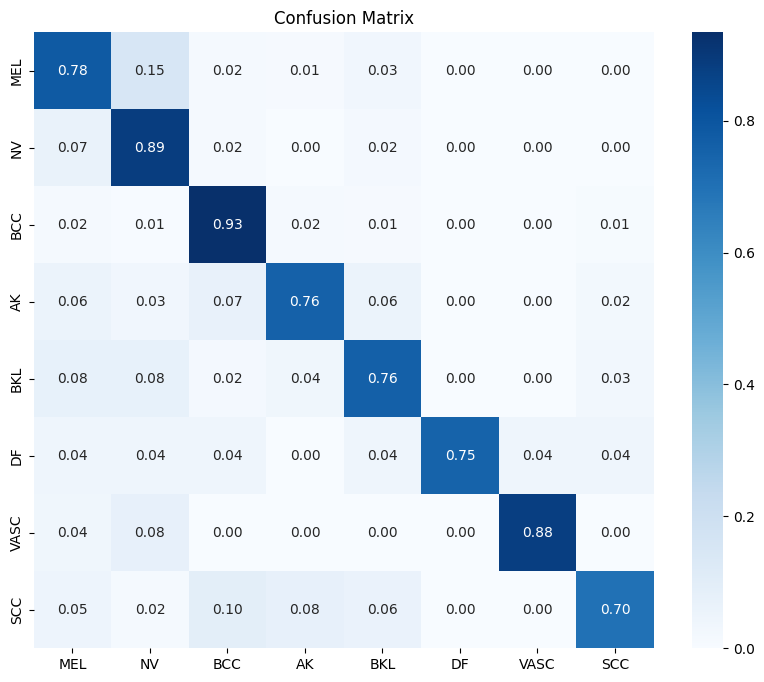

In [29]:
result = model.evaluate(test_dataset)
y_true = np.argmax(np.concatenate([y.numpy() for _, y in test_dataset]), axis=1)
y_pred = np.argmax(model.predict(test_dataset), axis=1)

print(classification_report(y_true, y_pred, target_names=LABELS))

conf_matrix = confusion_matrix(y_true, y_pred, normalize="true")
plt.figure(figsize=(10, 8))
sns.heatmap(conf_matrix, annot=True, cmap="Blues", fmt=".2f", xticklabels=LABELS, yticklabels=LABELS)
plt.title("Confusion Matrix")
plt.show()

# Fine-tuning

In [18]:
tf.compat.v1.enable_eager_execution()
model = tf.keras.models.load_model('/teamspace/studios/this_studio/models/weights/efficientnet-v2-m-onehot_baserun.keras')

/Users/mac/Library/Caches/pypoetry/virtualenvs/diploma-JhBIondL-py3.11/lib/python3.11/site-packages/keras/src/saving/saving_lib.py:757: UserWarning: Skipping variable loading for optimizer 'adam', because it has 1308 variables whereas the saved optimizer has 2 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


In [15]:
model.evaluate(test_dataset_2)

258/258 ━━━━━━━━━━━━━━━━━━━━ 580s 2s/step - accuracy: 0.5873 - loss: 0.8531 - precision: 0.6827 - recall: 0.5625


[0.8416513204574585,
 0.4922311305999756,
 0.5843790769577026,
 0.5039573311805725]

In [20]:
for layer in model.layers:
     if layer.name == 'efficientnetv2-m':
         layer.trainable = True
         for l in layer.layers[:-200]:
              l.trainable = False
         for l in layer.layers[-200:]:
              l.trainable = True
     if layer.name == 'batch_normalization_1':
         layer.trainable = False
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 456, 456, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetv2-m (Functional)   │ (None, 15, 15, 1280)   │    53,150,388 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1024)           │     1,311,744 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 1024)           │         4,096 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 8)              │         8,200 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 162,835,126 (621.17 MB)

 Trainable params: 31,530,196 (120.28 MB)

 Non-trainable params: 22,944,232 (87.53 MB)

 Optimizer params: 108,360,698 (413.36 MB)

In [21]:
checkpoint = ModelCheckpoint("efficientnet-v2-m-onehot_finetuning.keras", monitor="val_accuracy", save_best_only=True, mode="max", verbose=1)
history = model.fit(train_dataset, validation_data=test_dataset, epochs=EPOCHS, callbacks=[checkpoint],
                    class_weight=class_weights_dict)

Epoch 1/20


792/792 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.6119 - loss: 0.9054 - precision: 0.6894 - recall: 0.5100
Epoch 1: val_accuracy improved from -inf to 0.56555, saving model to efficientnet-v2-m-onehot_finetuning.keras
792/792 ━━━━━━━━━━━━━━━━━━━━ 2619s 3s/step - accuracy: 0.6118 - loss: 0.9058 - precision: 0.6894 - recall: 0.5099 - val_accuracy: 0.5656 - val_loss: 1.2173 - val_precision: 0.6631 - val_recall: 0.4442
Epoch 2/20
792/792 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.6558 - loss: 0.6761 - precision: 0.7386 - recall: 0.5603
Epoch 2: val_accuracy improved from 0.56555 to 0.62566, saving model to efficientnet-v2-m-onehot_finetuning.keras
792/792 ━━━━━━━━━━━━━━━━━━━━ 2177s 3s/step - accuracy: 0.6558 - loss: 0.6764 - precision: 0.7386 - recall: 0.5603 - val_accuracy: 0.6257 - val_loss: 1.0137 - val_precision: 0.6772 - val_recall: 0.5494
Epoch 3/20
792/792 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.6923 - loss: 0.5476 - precision: 0.7503 - recall: 0.6250
Epoch 3: val_accur

KeyboardInterrupt: 

In [ ]:
checkpoint = ModelCheckpoint("efficientnet-v2-m-onehot_finetuning.keras", monitor="val_accuracy", save_best_only=True, mode="max", verbose=1)
history = model.fit(train_dataset, validation_data=test_dataset_2, epochs=EPOCHS, callbacks=[checkpoint],
                    class_weight=class_weights_dict)

Epoch 1/20
792/792 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.7569 - loss: 0.3798 - precision: 0.7922 - recall: 0.7203
Epoch 1: val_accuracy improved from -inf to 0.50522, saving model to efficientnet-v2-m-onehot_finetuning.keras
792/792 ━━━━━━━━━━━━━━━━━━━━ 2074s 3s/step - accuracy: 0.7570 - loss: 0.3799 - precision: 0.7922 - recall: 0.7203 - val_accuracy: 0.5052 - val_loss: 0.9712 - val_precision: 0.5086 - val_recall: 0.6099
Epoch 2/20
792/792 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.7700 - loss: 0.3524 - precision: 0.7983 - recall: 0.7368
Epoch 2: val_accuracy did not improve from 0.50522
792/792 ━━━━━━━━━━━━━━━━━━━━ 2025s 3s/step - accuracy: 0.7700 - loss: 0.3524 - precision: 0.7984 - recall: 0.7369 - val_accuracy: 0.4942 - val_loss: 1.1084 - val_precision: 0.4868 - val_recall: 0.5870
Epoch 3/20
792/792 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.7780 - loss: 0.3390 - precision: 0.8038 - recall: 0.7458
Epoch 3: val_accuracy improved from 0.50522 to 0.51238, saving model t

In [40]:
model.save('efficientnet-v2-m-onehot_baserun.keras')